In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jayjoshi37/sleep-screen-time-and-stress-analysis/sleep_mobile_stress_dataset_15000.csv


In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/kaggle/input/datasets/jayjoshi37/sleep-screen-time-and-stress-analysis/sleep_mobile_stress_dataset_15000.csv")
df.head()

,user_id,age,gender,occupation,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes,notifications_received_per_day,mental_fatigue_score
0,1,56,Female,Designer,3.26,86,5.31,7.72,3.49,0,35,119,3.57
1,2,46,Female,Teacher,1.85,32,7.36,9.70,3.01,0,16,299,1.91
2,3,32,Female,Designer,3.04,107,4.50,6.38,5.03,0,17,21,6.05
3,4,25,Male,Software Engineer,9.00,36,6.68,5.53,10.00,0,3,220,9.92
4,5,38,Female,Teacher,3.52,56,7.57,6.69,6.71,4,92,167,5.99


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   user_id                           15000 non-null  int64  
 1   age                               15000 non-null  int64  
 2   gender                            15000 non-null  object 
 3   occupation                        15000 non-null  object 
 4   daily_screen_time_hours           15000 non-null  float64
 5   phone_usage_before_sleep_minutes  15000 non-null  int64  
 6   sleep_duration_hours              15000 non-null  float64
 7   sleep_quality_score               15000 non-null  float64
 8   stress_level                      15000 non-null  float64
 9   caffeine_intake_cups              15000 non-null  int64  
 10  physical_activity_minutes         15000 non-null  int64  
 11  notifications_received_per_day    15000 non-null  int64  
 12  ment

- Only `Gender` and `occupation` is object datatype

In [23]:
print("Total Unique Gender:",df['gender'].nunique())
print("Total Unique number of occupation:",df['occupation'].nunique(),end='\n\n')

print(df['gender'].value_counts(),end="\n\n")
print(df['occupation'].value_counts())

Total Unique Gender: 3
Total Unique number of occupation: 8

gender
Male      7234
Female    7181
Other      585
Name: count, dtype: int64

occupation
Manager              1962
Doctor               1922
Software Engineer    1917
Freelancer           1891
Student              1861
Researcher           1837
Designer             1813
Teacher              1797
Name: count, dtype: int64


In [24]:
df.isna().sum()

user_id                             0
age                                 0
gender                              0
occupation                          0
daily_screen_time_hours             0
phone_usage_before_sleep_minutes    0
sleep_duration_hours                0
sleep_quality_score                 0
stress_level                        0
caffeine_intake_cups                0
physical_activity_minutes           0
notifications_received_per_day      0
mental_fatigue_score                0
dtype: int64

- No Empty Values

In [26]:
df.duplicated().sum()

np.int64(0)

- There's no duplicate values

In [30]:
df.describe().loc[['50%','mean'],:]

,user_id,age,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes,notifications_received_per_day,mental_fatigue_score
50%,7500.5,38.000000,5.490000,60.000000,6.490000,6.250000,7.380000,2.0000,59.000000,162.000000,7.380000
mean,7500.5,38.488467,5.501528,59.708933,6.509683,6.246362,6.980247,1.9988,59.157133,160.890467,6.873009


In [43]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,15000.0,7500.500000,4330.271354,1.0,3750.75,7500.50,11250.25,15000.0
age,15000.0,38.488467,12.007970,18.0,28.00,38.00,49.00,59.0
daily_screen_time_hours,15000.0,5.501528,2.600085,1.0,3.26,5.49,7.76,10.0
phone_usage_before_sleep_minutes,15000.0,59.708933,34.641858,0.0,29.00,60.00,90.00,119.0
sleep_duration_hours,15000.0,6.509683,1.452689,4.0,5.26,6.49,7.79,9.0
sleep_quality_score,15000.0,6.246362,1.713644,1.0,5.00,6.25,7.50,10.0
stress_level,15000.0,6.980247,2.749382,1.0,4.75,7.38,10.00,10.0
caffeine_intake_cups,15000.0,1.998800,1.414590,0.0,1.00,2.00,3.00,4.0
physical_activity_minutes,15000.0,59.157133,34.525705,0.0,29.00,59.00,89.00,119.0
notifications_received_per_day,15000.0,160.890467,80.856902,20.0,92.00,162.00,231.00,299.0


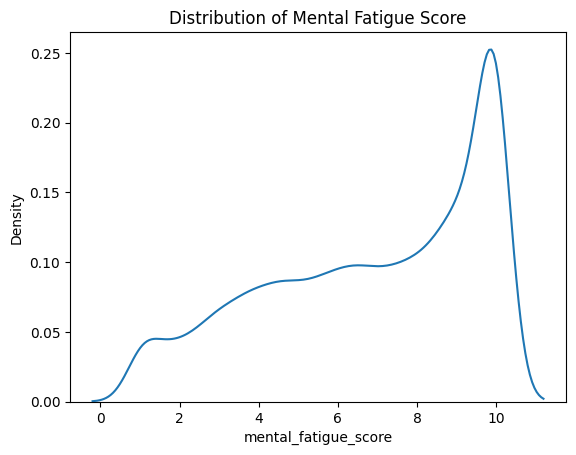

In [41]:
sns.kdeplot(data=df,x='mental_fatigue_score')
plt.title("Distribution of Mental Fatigue Score")
plt.show()

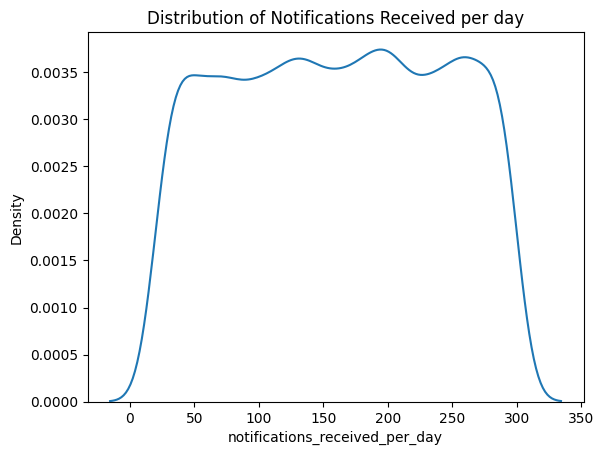

In [46]:
sns.kdeplot(data=df,x='notifications_received_per_day')
plt.title("Distribution of Notifications Received per day")
plt.show()

In [44]:
summary = df.describe().T

summary['mean_median_diff'] = (
    summary['mean'] - summary['50%']
)

display(summary)

,count,mean,std,min,25%,50%,75%,max,mean_median_diff
user_id,15000.0,7500.500000,4330.271354,1.0,3750.75,7500.50,11250.25,15000.0,0.000000
age,15000.0,38.488467,12.007970,18.0,28.00,38.00,49.00,59.0,0.488467
daily_screen_time_hours,15000.0,5.501528,2.600085,1.0,3.26,5.49,7.76,10.0,0.011528
phone_usage_before_sleep_minutes,15000.0,59.708933,34.641858,0.0,29.00,60.00,90.00,119.0,-0.291067
sleep_duration_hours,15000.0,6.509683,1.452689,4.0,5.26,6.49,7.79,9.0,0.019683
sleep_quality_score,15000.0,6.246362,1.713644,1.0,5.00,6.25,7.50,10.0,-0.003638
stress_level,15000.0,6.980247,2.749382,1.0,4.75,7.38,10.00,10.0,-0.399753
caffeine_intake_cups,15000.0,1.998800,1.414590,0.0,1.00,2.00,3.00,4.0,-0.001200
physical_activity_minutes,15000.0,59.157133,34.525705,0.0,29.00,59.00,89.00,119.0,0.157133
notifications_received_per_day,15000.0,160.890467,80.856902,20.0,92.00,162.00,231.00,299.0,-1.109533
